# WP007 — Structural fixes: rigid dynamics, promoted teams, xG, DC bug, forecasting

Readout of the arms × windows sweep from `run_cv.py` (see this folder's README for the motivation behind each rung and the diagnostics that predicted it). Every comparison is **paired** on identical test matches. Run `python run_cv.py` first.

In [1]:
import sys, pickle, warnings
sys.path.insert(0, '.')
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from analysis import *
from arms import ARMS, LADDER

pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)
df_cv = pickle.load(open('cv_shared_data.pkl', 'rb'))['df_cv']
matches, wins = load_checkpoints()
matches = attach_meta(matches, df_cv)

per_arm = matches.groupby('arm')['window'].nunique().reindex(list(ARMS))
print('windows completed per arm:'); print(per_arm.to_string())
have = complete_windows(matches, [a for a in ARMS if a in set(matches.arm)])
M = matches[matches.window.isin(have)]
n_matches = M[M.arm == LADDER[0]].shape[0]
print(f'\npaired comparisons use the {len(have)} windows finished by EVERY arm = {n_matches} matches')

windows completed per arm:
arm
L0_baseline         30
L1_posterior        30
L2_level            30
L3_randomwalk       30
L4_promoted         30
L5_xgchannel        30
L6_dixoncoles       30
S1_xgweight1        30
S2_dc_only_fixed    30

paired comparisons use the 30 windows finished by EVERY arm = 1314 matches


## 1. The ladder — one change per rung, paired on the same matches

`Δ vs prev` is the effect of that rung's single change; `Δ vs L0` is cumulative. Negative RPS difference = better. Two CIs are shown: **match-level** bootstrap (what WP001–006 used) and **window-cluster** bootstrap (resamples whole CV windows — matches inside one window share a single fit, so the match-level interval is too narrow; the cluster interval is the conservative one).

In [2]:
R  = wide(M, 'rps', LADDER)
LL = wide(M, 'll_goals', LADDER)
grp = R.index.get_level_values('window')
mae = (M.assign(ae=(M.lambda_home - M.goals_home).abs() + (M.lambda_away - M.goals_away).abs())
         .pivot_table(index=['window','round','home','away'], columns='arm', values='ae')[LADDER] / 2)

rows = []
for i, a in enumerate(LADDER):
    r = {'arm': a, 'RPS': R[a].mean(), 'LL/match': LL[a].mean(), 'MAE': mae[a].mean()}
    if i:
        d, lo, hi = paired_diff(R[a], R[LADDER[i-1]], groups=grp)
        r.update({'Δ vs prev': d, 'prev CI (cluster)': f'[{lo:+.4f}, {hi:+.4f}]', 'prev verdict': verdict(lo, hi)})
        d0, l0, h0 = paired_diff(R[a], R[LADDER[0]])
        d0c, l0c, h0c = paired_diff(R[a], R[LADDER[0]], groups=grp)
        r.update({'Δ vs L0': d0, 'L0 CI (match)': f'[{l0:+.4f}, {h0:+.4f}]',
                  'L0 CI (cluster)': f'[{l0c:+.4f}, {h0c:+.4f}]', 'L0 verdict': verdict(l0c, h0c)})
    rows.append(r)
ladder = pd.DataFrame(rows)
print(ladder.round(4).to_string(index=False))

          arm    RPS  LL/match    MAE  Δ vs prev  prev CI (cluster)        prev verdict  Δ vs L0      L0 CI (match)    L0 CI (cluster)          L0 verdict
  L0_baseline 0.2074   -3.0043 0.9280        NaN                NaN                 NaN      NaN                NaN                NaN                 NaN
 L1_posterior 0.2075   -3.0043 0.9296     0.0001 [-0.0002, +0.0004] no clear difference   0.0001 [-0.0001, +0.0003] [-0.0002, +0.0004] no clear difference
     L2_level 0.2077   -3.0090 0.9271     0.0002 [-0.0002, +0.0006] no clear difference   0.0004 [-0.0000, +0.0007] [-0.0000, +0.0007] no clear difference
L3_randomwalk 0.2075   -3.0105 0.9276    -0.0003 [-0.0012, +0.0007] no clear difference   0.0001 [-0.0006, +0.0008] [-0.0007, +0.0010] no clear difference
  L4_promoted 0.2077   -3.0120 0.9287     0.0002 [-0.0003, +0.0006] no clear difference   0.0003 [-0.0006, +0.0011] [-0.0006, +0.0012] no clear difference
 L5_xgchannel 0.2049   -2.9944 0.9222    -0.0028 [-0.0048, -0.0007]   

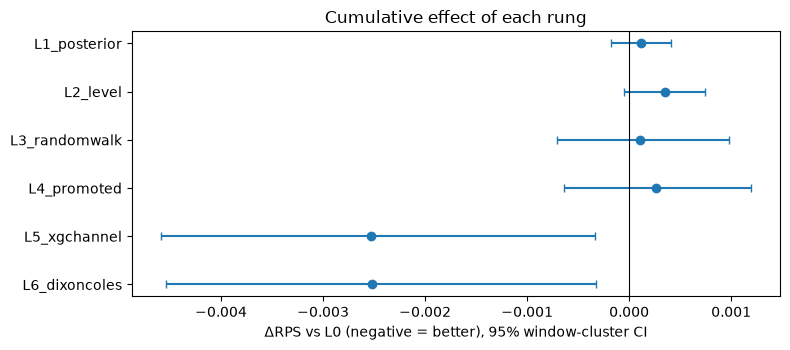

In [3]:
fig, ax = plt.subplots(figsize=(8, 3.6))
for i, a in enumerate(LADDER[1:], 1):
    d, lo, hi = paired_diff(R[a], R[LADDER[0]], groups=grp)
    ax.errorbar(d, i, xerr=[[d - lo], [hi - d]], fmt='o', color='#1f77b4', capsize=3)
ax.axvline(0, color='k', lw=0.8)
ax.set_yticks(range(1, len(LADDER))); ax.set_yticklabels(LADDER[1:]); ax.invert_yaxis()
ax.set_xlabel('ΔRPS vs L0 (negative = better), 95% window-cluster CI'); ax.set_title('Cumulative effect of each rung')
plt.tight_layout(); plt.show()

## 2. Side arms — the questions the ladder doesn't answer

* **S2 vs L0** — the old model with *only* the Dixon-Coles tau fix. WP002 concluded DC does nothing under the buggy (improper) tau; does that survive the fix?
* **L6 vs L5** — DC on top of the full model.
* **S1 vs L5** — xG channel at full weight instead of 0.5.

In [4]:
side = [('S2_dc_only_fixed', 'L0_baseline', 'DC fixed alone vs old model'),
        ('L6_dixoncoles', 'L5_xgchannel', 'DC on top of full model'),
        ('S1_xgweight1', 'L5_xgchannel', 'xG weight 1.0 vs 0.5')]
rows = []
for a, b, label in side:
    R2 = wide(M, 'rps', [a, b]); g = R2.index.get_level_values('window')
    d, lo, hi = paired_diff(R2[a], R2[b], groups=g); dm, lm, hm = paired_diff(R2[a], R2[b])
    rows.append({'comparison': label, 'ΔRPS': round(d, 5), 'CI (cluster)': f'[{lo:+.4f}, {hi:+.4f}]',
                 'CI (match)': f'[{lm:+.4f}, {hm:+.4f}]', 'verdict': verdict(lo, hi)})
print(pd.DataFrame(rows).to_string(index=False))

                 comparison     ΔRPS       CI (cluster)         CI (match)             verdict
DC fixed alone vs old model  0.00006 [-0.0001, +0.0002] [-0.0000, +0.0002] no clear difference
    DC on top of full model  0.00002 [-0.0002, +0.0002] [-0.0001, +0.0002] no clear difference
       xG weight 1.0 vs 0.5 -0.00052 [-0.0019, +0.0009] [-0.0019, +0.0008] no clear difference


## 3. What the model learned

Posterior means of the scalar parameters, median across windows. These test whether the fitted values match the diagnostics that motivated each rung: a promotion shift near −0.37 attack / −0.26 defence, per-round walk sigma implying a season-scale change near 0.12, an `xg_shape` near the empirical Gamma shape (~3–5).

In [5]:
pc = [c for c in wins.columns if c.startswith('param_')]
lp = wins.groupby('arm')[pc].median().reindex(list(ARMS)).dropna(axis=1, how='all')
lp.columns = [c.replace('param_', '') for c in lp.columns]
print(lp.round(3).to_string())
for a in ['L3_randomwalk', 'L4_promoted', 'L5_xgchannel']:
    if a in lp.index and 'sigma_att' in lp.columns:
        s = lp.loc[a, 'sigma_att']
        print(f"{a}: sigma_att={s:.3f}/round -> implied 1-season (38-round) change SD ≈ {s*np.sqrt(38):.3f}   (data-based estimate ≈ 0.12)")

                  sigma_att  sigma_def  home_mu  rho_att  rho_def  home_sd  intercept  promo_att  promo_def  xg_shape  xg_kappa  rho_dc
arm                                                                                                                                    
L0_baseline           0.013      0.016    0.196    0.997    0.984    0.016        NaN        NaN        NaN       NaN       NaN     NaN
L1_posterior          0.013      0.016    0.196    0.997    0.984    0.016        NaN        NaN        NaN       NaN       NaN     NaN
L2_level              0.013      0.016    0.216    0.996    0.985    0.031      0.136        NaN        NaN       NaN       NaN     NaN
L3_randomwalk         0.012      0.012    0.217      NaN      NaN    0.031      0.134        NaN        NaN       NaN       NaN     NaN
L4_promoted           0.012      0.012    0.217      NaN      NaN    0.032      0.134     -0.069     -0.037       NaN       NaN     NaN
L5_xgchannel          0.014      0.015    0.224 

## 4. Calibration — the under-confidence at high home-win probability

WP001 found predicted 0.6–0.8 → actual 0.75 and 0.8–0.9 → actual 0.93. Did the restructuring fix it?

In [6]:
best = ladder.loc[ladder['RPS'].idxmin(), 'arm']
print('lowest-RPS ladder arm:', best, '\n')
for a in [LADDER[0], best]:
    d = M[M.arm == a]
    print(f'{a}  — predicted P(home win) vs actual'); print(reliability_table(d.p_home, (d.result == 'H')).to_string(index=False), '\n')

lowest-RPS ladder arm: L5_xgchannel 

L0_baseline  — predicted P(home win) vs actual
      bin   n  pred  actual
0.00-0.12  29 0.102   0.069
0.12-0.25 161 0.199   0.137
0.25-0.38 314 0.317   0.338
0.38-0.50 354 0.434   0.429
0.50-0.62 263 0.559   0.540
0.62-0.75 137 0.679   0.657
0.75-0.88  54 0.789   0.889
0.88-1.00   2 0.883   1.000 

L5_xgchannel  — predicted P(home win) vs actual
      bin   n  pred  actual
0.00-0.12  36 0.093   0.056
0.12-0.25 157 0.198   0.178
0.25-0.38 298 0.316   0.302
0.38-0.50 332 0.434   0.428
0.50-0.62 253 0.558   0.526
0.62-0.75 167 0.679   0.641
0.75-0.88  68 0.798   0.868
0.88-1.00   3 0.895   1.000 



## 5. Where should the promoted-team offset help? Matches involving a newly promoted side

In [7]:
seasons = sorted(df_cv.season.unique())
steams = {s: set(g.team) | set(g.opp_team) for s, g in df_cv.groupby('season')}
promoted = {s: steams[s] - steams[seasons[i-1]] for i, s in enumerate(seasons) if i}
Mp = M.copy()
Mp['has_promoted'] = [(h in promoted.get(s, set())) or (a in promoted.get(s, set()))
                      for h, a, s in zip(Mp.home, Mp.away, Mp.season)]
rows = []
for label, sel in [('promoted side, season rounds 1-10', Mp.has_promoted & (Mp.season_round <= 10)),
                   ('promoted side, round 11+', Mp.has_promoted & (Mp.season_round > 10)),
                   ('no promoted side', ~Mp.has_promoted)]:
    S = Mp[sel]
    if S.arm.eq(LADDER[0]).sum() == 0: continue
    R3 = wide(S, 'rps', [LADDER[0], best]); g = R3.index.get_level_values('window')
    d, lo, hi = paired_diff(R3[best], R3[LADDER[0]], groups=g)
    rows.append({'subset': label, 'n': len(R3), f'RPS {LADDER[0]}': round(R3[LADDER[0]].mean(), 4),
                 f'RPS {best}': round(R3[best].mean(), 4), 'Δ': round(d, 4), 'CI (cluster)': f'[{lo:+.4f}, {hi:+.4f}]'})
print(pd.DataFrame(rows).to_string(index=False))

                           subset   n  RPS L0_baseline  RPS L5_xgchannel       Δ       CI (cluster)
promoted side, season rounds 1-10  91           0.1969            0.1961 -0.0007 [-0.0087, +0.0074]
         promoted side, round 11+ 285           0.1941            0.1919 -0.0022 [-0.0065, +0.0018]
                 no promoted side 938           0.2125            0.2096 -0.0028 [-0.0049, -0.0005]


## 6. Stability across seasons — is the gain one lucky season?

In [8]:
rows = []
for s, S in M.groupby('season'):
    R4 = wide(S, 'rps', [LADDER[0], best]); g = R4.index.get_level_values('window')
    d, lo, hi = paired_diff(R4[best], R4[LADDER[0]], groups=g)
    rows.append({'season': s, 'n': len(R4), f'RPS {LADDER[0]}': round(R4[LADDER[0]].mean(), 4),
                 f'RPS {best}': round(R4[best].mean(), 4), 'Δ': round(d, 4), 'CI (cluster)': f'[{lo:+.4f}, {hi:+.4f}]'})
print(pd.DataFrame(rows).to_string(index=False))

season   n  RPS L0_baseline  RPS L5_xgchannel       Δ       CI (cluster)
  2020 223           0.2298            0.2299  0.0001 [-0.0054, +0.0068]
  2021 220           0.1915            0.1898 -0.0017 [-0.0051, +0.0013]
  2022 205           0.2181            0.2138 -0.0043 [-0.0097, +0.0019]
  2023 228           0.1822            0.1796 -0.0025 [-0.0078, +0.0031]
  2024 219           0.2034            0.1960 -0.0074 [-0.0096, -0.0043]
  2025 219           0.2207            0.2211  0.0004 [-0.0021, +0.0029]


## 7. Against the market (Pinnacle closing odds, de-vigged)

The yardstick WP003 set: the model was +0.0139 RPS behind Pinnacle (95% CI [+0.0080, +0.0198]). Loads odds via `analysis.load_odds` (reuses WP003's `odds_raw.pkl` if present; otherwise fetches football-data.co.uk). If odds are unavailable this section reports so instead of failing.

In [9]:
odds = load_odds()
if odds is None:
    print('odds unavailable — Pinnacle benchmark PENDING (re-run this cell when football-data.co.uk is reachable)')
else:
    ident = M[M.arm == LADDER[0]][['window', 'round', 'home', 'away', 'date', 'result']]
    J = attach_pinnacle(ident, odds)
    ok = J[['pin_h', 'pin_d', 'pin_a']].notna().all(axis=1).to_numpy()
    print(f'{ok.sum()}/{len(J)} matches have Pinnacle closing odds')
    key = ['window', 'round', 'home', 'away']
    J = J[ok].set_index(key)
    pin_rps = pd.Series(rps_hda(J[['pin_h', 'pin_d', 'pin_a']].to_numpy(), J['result']), index=J.index)
    Rk = wide(M, 'rps', LADDER).loc[J.index]; g = Rk.index.get_level_values('window')
    print(f'Pinnacle pooled RPS on these matches: {pin_rps.mean():.4f}\n')
    gap0 = (Rk[LADDER[0]] - pin_rps)
    rows = []
    for a in LADDER:
        gap = Rk[a] - pin_rps
        d, lo, hi = bootstrap_mean_ci(gap.values, groups=g)
        closed = 1 - gap.mean() / gap0.mean() if a != LADDER[0] else 0.0
        rows.append({'arm': a, 'RPS': round(Rk[a].mean(), 4), 'gap vs Pinnacle': round(d, 4),
                     'CI (cluster)': f'[{lo:+.4f}, {hi:+.4f}]', 'gap closed vs L0': f'{closed:.0%}'})
    print(pd.DataFrame(rows).to_string(index=False))

odds 2021 unavailable: URLError
odds unavailable — Pinnacle benchmark PENDING (re-run this cell when football-data.co.uk is reachable)


## 8. Sampler health

In [10]:
diag = wins.groupby('arm').agg(windows=('window', 'nunique'), divergences=('n_diverging', 'sum'),
                              rhat_median=('max_rhat', 'median'), rhat_max=('max_rhat', 'max'),
                              sec_per_window=('seconds', 'mean')).reindex(list(ARMS)).round(3)
print(diag.to_string())

                  windows  divergences  rhat_median  rhat_max  sec_per_window
arm                                                                          
L0_baseline            30            0        1.012     1.028         271.724
L1_posterior           30            0        1.012     1.028         258.546
L2_level               30            0        1.011     1.026         289.753
L3_randomwalk          30            0        1.007     1.021         231.532
L4_promoted            30            0        1.005     1.012         235.619
L5_xgchannel           30            0        1.005     1.015         331.103
L6_dixoncoles          30            0        1.006     1.012         363.930
S1_xgweight1           30            0        1.007     1.017         453.071
S2_dc_only_fixed       30            0        1.012     1.029         256.882
